# CDS 321 — Multilingual Analysis of UEFA Euro 2024 Match Reports

**Final Research Project — Natural Language Processing**

**Sources:** BBC (English), Marca (Spanish), Kicker (German)

## Research Question

How do football news reports about the same match compare in sentiment, domain-specific vocabulary, and cross-lingual semantic representation?

Can multilingual embeddings retrieve the corresponding article across languages, and how much do player names contribute to retrieval performance?

## Dataset Overview

- Dataset: SocCor
- Competition: UEFA Euro 2024
- Matches: 51
- News sources: 3
- Total articles: 153
- Languages: English, Spanish, German

**Important methodological limitation:** Each source corresponds to one language. Consequently, source-specific differences cannot be attributed exclusively to language.

This notebook presents the final corrected analyses. Exploratory debugging, intermediate model runs, and manual audit iterations are retained separately in the original development notebook.

## 1. Setup and Reproducibility

This project was developed using Python and Google Colab.

### Main Libraries

- NumPy — Numerical computations
- pandas — Data processing
- SciPy — Statistical hypothesis testing
- statsmodels — Multiple-testing corrections and McNemar test
- Matplotlib — Data visualization
- Requests — Public corpus acquisition

### Public Repositories

Project repository:

https://github.com/JaviMontava/CDS321-Final-NLP-Project

Original SocCor dataset:

https://github.com/PaulLoehr/SocCor

### Project Directory

The project repository is automatically cloned into the local execution environment.

The repository contains:

- `data/` — Validated document ordering and dataset alignment information.
- `results/` — Cached NLP outputs, document embeddings, and associated metadata.
- `requirements.txt` — Project dependencies.

No personal Google Drive access is required.

### Execution Instructions

1. Open this notebook in Google Colab.
2. Keep `RUN_UPSTREAM = False`.
3. Select Runtime → Run all.
4. Verify that the dataset reproducibility validation reports `VALIDATION: PASSED`.

The original corpus is downloaded directly from SocCor, preprocessed, corrected, and reordered automatically.

### Reproducibility Scope

The default execution reconstructs the dataset and uses validated cached NLP outputs to reproduce the final statistical analyses, retrieval metrics, ablation experiments, and visualizations.

An optional upstream pipeline is included for model regeneration. This pipeline has not been independently validated as a complete uninterrupted execution.

In [1]:
# ============================================================
# CDS 321 — FINAL PROJECT
# 1. ENVIRONMENT SETUP AND GITHUB ACCESS
# ============================================================

from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    friedmanchisquare,
    wilcoxon
)

from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar

# Public project repository
REPO_URL = (
    "https://github.com/JaviMontava/"
    "CDS321-Final-NLP-Project.git"
)

# Original public dataset repository
SOCCOR_URL = "https://github.com/PaulLoehr/SocCor"

# Local project directory
BASE = Path.cwd() / "CDS321-Final-NLP-Project"

# Download project files directly from GitHub
if not BASE.exists():

    subprocess.run(
        ["git", "clone", REPO_URL, str(BASE)],
        check=True
    )

else:

    subprocess.run(
        ["git", "-C", str(BASE), "pull", "--ff-only"],
        check=True
    )

DATA = BASE / "data"
RESULTS = BASE / "results"

# Verify directory availability
assert DATA.is_dir(), "Data directory not found."
assert RESULTS.is_dir(), "Results directory not found."

# Verify required reproducibility files
required_files = [
    DATA / "dataset_row_order.csv",
    RESULTS / "euro2024_sentiment_results_corrected_v2.csv",
    RESULTS / "euro2024_football_vocabulary.csv",
    RESULTS / "euro2024_tfidf_improved.csv",
    RESULTS / "euro2024_document_embeddings_corrected_v2.npy",
    RESULTS / "euro2024_ablation_embeddings_corrected_v2.npy",
    RESULTS / "euro2024_embedding_metadata_corrected_v2.csv",
    RESULTS / "euro2024_ablation_metadata_corrected_v2.csv"
]

for file in required_files:
    assert file.is_file(), f"Missing file: {file.name}"

print("=" * 60)
print("CDS 321 — PROJECT ENVIRONMENT READY")
print("=" * 60)

print("Project repository:", REPO_URL)
print("Original dataset:", SOCCOR_URL)
print("Project directory:", BASE)
print("Required files verified:", len(required_files))
print("Google Drive required: NO")
print("\nSUCCESS: GITHUB ENVIRONMENT READY")

CDS 321 — PROJECT ENVIRONMENT READY
Project repository: https://github.com/JaviMontava/CDS321-Final-NLP-Project.git
Original dataset: https://github.com/PaulLoehr/SocCor
Project directory: /content/CDS321-Final-NLP-Project
Required files verified: 8
Google Drive required: NO

SUCCESS: GITHUB ENVIRONMENT READY


## Upstream NLP Pipeline: Raw Corpus, Preprocessing, and Model Inference

### Reproduction Modes

**Default mode — RUN_UPSTREAM = False**

The notebook automatically downloads and reconstructs the original SocCor dataset and loads the validated cached NLP outputs from the public project repository.

This mode reproduces the final statistical analyses and visualizations without downloading transformer model weights.

**Optional mode — RUN_UPSTREAM = True**

The following cells also implement an optional upstream pipeline that attempts to:

1. Download the public SocCor articles and metadata.
2. Normalize player and entity annotations.
3. Apply documented article-alignment corrections.
4. Compute multilingual sentiment predictions.
5. Generate multilingual document embeddings.
6. Generate player-masked embeddings for the ablation study.

### Important Reproducibility Notes

The corrected dataset includes manually audited article-to-match swaps:

- Marca: 17 ↔ 18
- BBC: 49 ↔ 50
- Marca: 49 ↔ 50

The reconstructed dataset is validated against the original research dataset using a SHA256 fingerprint.

Regenerated model outputs are saved separately in `upstream_regenerated/` and do not overwrite the validated corrected-v2 research artifacts.

The downstream analyses continue to use the validated cached outputs.

Differences in regenerated outputs may arise from model versions, package versions, numerical precision, and chunking implementations.

The optional upstream model regeneration workflow has not yet been independently verified from beginning to end.

In [2]:
# ============================================================
# UPSTREAM REGENERATION CONFIGURATION
# ============================================================

# False = use cached corrected results (recommended)
# True  = download corpus and rerun NLP models

RUN_UPSTREAM = False

UPSTREAM = BASE / "upstream_regenerated"

if RUN_UPSTREAM:
    UPSTREAM.mkdir(
        parents=True,
        exist_ok=True
    )

print(
    "Upstream model regeneration:",
    "ENABLED" if RUN_UPSTREAM
    else "SKIPPED (cached results)"
)

Upstream model regeneration: SKIPPED (cached results)


In [3]:
import re


def semantic_clean(text):
    """Remove SocCor annotations while preserving player names."""

    def replace(match):
        return (
            match.group(1)
            .split("_")[0]
            .replace("-", " ")
        )

    cleaned = re.sub(r"<([^<>]+)>", replace, str(text))
    cleaned = re.sub(r"\s+", " ", cleaned).strip()
    cleaned = re.sub(r"\s+([.,!?;:])", r"\1", cleaned)

    return cleaned


def mask_players(text):
    """Replace entity annotations with a generic PLAYER token."""

    masked = re.sub(r"<[^<>]+>", " PLAYER ", str(text))
    masked = re.sub(r"\s+", " ", masked).strip()
    masked = re.sub(r"\s+([.,!?;:])", r"\1", masked)

    return masked


def original_word_count(text):
    """Reproduce the original pre-normalization token count."""

    masked = re.sub(r"<[^<>]+>", " PLAYER ", str(text))
    masked = re.sub(r"\s+", " ", masked).strip()

    return len(masked.split())


def download_soccor():
    """Download and reconstruct the corrected Euro 2024 dataset."""

    import requests
    from io import StringIO

    root = (
        "https://raw.githubusercontent.com/"
        "PaulLoehr/SocCor/main/SocCor"
    )

    response = requests.get(
        f"{root}/Metadata/Games.csv",
        timeout=60
    )
    response.raise_for_status()

    games = pd.read_csv(
        StringIO(response.text),
        sep=";"
    )

    api = (
        "https://api.github.com/repos/"
        "PaulLoehr/SocCor/contents/"
        "SocCor/Textdata/cleaned_data/Reports"
    )

    rows = []

    source_languages = [
        ("BBC", "English"),
        ("Marca", "Spanish"),
        ("Kicker", "German")
    ]

    # Download the original match reports.
    with requests.Session() as session:

        for source, language in source_languages:

            response = session.get(
                f"{api}/{source}",
                timeout=60
            )
            response.raise_for_status()

            for entry in response.json():

                if not entry["name"].endswith(".json"):
                    continue

                match_id = int(
                    entry["name"].split("_")[0]
                )

                report = session.get(
                    entry["download_url"],
                    timeout=60
                )
                report.raise_for_status()

                article = report.json().get("text", "")

                rows.append({
                    "match_id": match_id,
                    "source": source,
                    "language": language,
                    "text": article,
                    "word_count": len(article.split())
                })

    # Merge reports with match metadata.
    raw = pd.DataFrame(rows).merge(
        games,
        left_on="match_id",
        right_on="game_id",
        how="left",
        validate="many_to_one"
    )

    assert len(raw) == 153
    assert raw["match_id"].nunique() == 51

    # Preserve the original article text.
    raw["text_original"] = raw["text"]

    # Reproduce the validated NLP preprocessing.
    raw["text_clean"] = raw["text"].map(
        mask_players
    )

    raw["text_semantic"] = raw["text"].map(
        semantic_clean
    )

    # Preserve the original token-count convention:
    # count tokens before punctuation-space normalization.
    raw["clean_word_count"] = raw["text"].map(
        original_word_count
    )

    # Correct the identified article-to-match mismatches.
    article_columns = [
        "text",
        "word_count",
        "text_original",
        "text_clean",
        "clean_word_count",
        "text_semantic"
    ]

    corrections = [
        ("Marca", 17, 18),
        ("BBC", 49, 50),
        ("Marca", 49, 50)
    ]

    for source, match_a, match_b in corrections:

        idx_a = raw.index[
            (raw["source"] == source) &
            (raw["match_id"] == match_a)
        ]

        idx_b = raw.index[
            (raw["source"] == source) &
            (raw["match_id"] == match_b)
        ]

        assert len(idx_a) == 1
        assert len(idx_b) == 1

        value_a = raw.loc[
            idx_a[0], article_columns
        ].copy()

        value_b = raw.loc[
            idx_b[0], article_columns
        ].copy()

        raw.loc[
            idx_a[0], article_columns
        ] = value_b.to_numpy()

        raw.loc[
            idx_b[0], article_columns
        ] = value_a.to_numpy()

    return raw


# Optional upstream regeneration.
if RUN_UPSTREAM:

    raw_regenerated = download_soccor()

    raw_regenerated.to_csv(
        UPSTREAM / "soccor_corrected_regenerated.csv",
        index=False
    )

In [4]:
# ============================================================
# MULTILINGUAL SENTIMENT MODEL INFERENCE
# ============================================================

def regenerate_sentiment(articles):
    """Compute chunk-weighted multilingual sentiment scores."""

    import torch
    import torch.nn.functional as F

    from transformers import (
        AutoTokenizer,
        AutoModelForSequenceClassification
    )

    model_name = (
        "cardiffnlp/"
        "twitter-xlm-roberta-base-sentiment"
    )

    tokenizer = AutoTokenizer.from_pretrained(
        model_name
    )

    model = (
        AutoModelForSequenceClassification
        .from_pretrained(model_name)
    )

    device = (
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )

    model.to(device).eval()

    results = []

    for _, row in articles.iterrows():

        token_ids = tokenizer.encode(
            str(row["text_semantic"]),
            add_special_tokens=False
        )

        chunks = [
            token_ids[i:i + 256]
            for i in range(0, len(token_ids), 256)
        ]

        if not chunks:
            chunks = [[]]

        weighted = np.zeros(
            3,
            dtype=float
        )

        total = 0

        for chunk in chunks:

            encoded = tokenizer.prepare_for_model(
                chunk,
                return_tensors="pt",
                truncation=True,
                max_length=258
            )

            encoded = {
                key: value.to(device)
                for key, value in encoded.items()
            }

            with torch.inference_mode():

                probabilities = F.softmax(
                    model(**encoded).logits,
                    dim=-1
                )[0].cpu().numpy()

            weight = max(len(chunk), 1)

            weighted += probabilities * weight
            total += weight

        probabilities = weighted / total

        results.append({
            "match_id": row["match_id"],
            "source": row["source"],
            "language": row["language"],
            "negative": probabilities[0],
            "neutral": probabilities[1],
            "positive": probabilities[2],
            "sentiment_score": (
                probabilities[2]
                - probabilities[0]
            )
        })

    return pd.DataFrame(results)


if RUN_UPSTREAM:

    regenerated_sentiment = regenerate_sentiment(
        raw_regenerated
    )

    regenerated_sentiment.to_csv(
        UPSTREAM / "sentiment_regenerated.csv",
        index=False
    )

    print(
        "Regenerated sentiment:",
        regenerated_sentiment.shape
    )

In [5]:
# ============================================================
# MULTILINGUAL DOCUMENT EMBEDDING GENERATION
# ============================================================

def regenerate_embeddings(articles, column):
    """Generate document embeddings from token-safe chunks."""

    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer(
        "sentence-transformers/"
        "paraphrase-multilingual-MiniLM-L12-v2"
    )

    max_content = min(
        100,
        model.max_seq_length - 2
    )

    tokenizer = model.tokenizer

    vectors = []

    for text in articles[column].astype(str):

        chunks = []
        current = []

        sentences = re.split(
            r"(?<=[.!?])\s+",
            text.strip()
        )

        for sentence in sentences:

            token_ids = tokenizer.encode(
                sentence,
                add_special_tokens=False
            )

            for start in range(
                0,
                len(token_ids),
                max_content
            ):

                part = token_ids[
                    start:start + max_content
                ]

                if (
                    len(current) + len(part)
                    > max_content
                    and current
                ):

                    chunks.append(
                        tokenizer.decode(
                            current,
                            skip_special_tokens=True
                        )
                    )

                    current = []

                current.extend(part)

        if current:

            chunks.append(
                tokenizer.decode(
                    current,
                    skip_special_tokens=True
                )
            )

        if not chunks:
            chunks = [""]

        chunk_vectors = model.encode(
            chunks,
            convert_to_numpy=True,
            normalize_embeddings=True,
            show_progress_bar=False
        )

        vector = chunk_vectors.mean(axis=0)

        norm = np.linalg.norm(vector)

        vectors.append(
            vector / norm if norm else vector
        )

    return np.stack(vectors)


if RUN_UPSTREAM:

    configurations = [
        (
            "text_semantic",
            "embeddings_regenerated.npy"
        ),
        (
            "text_clean",
            "player_masked_embeddings_regenerated.npy"
        )
    ]

    for column, filename in configurations:

        regenerated = regenerate_embeddings(
            raw_regenerated,
            column
        )

        assert regenerated.shape == (153, 384)

        np.save(
            UPSTREAM / filename,
            regenerated
        )

        print(
            filename,
            regenerated.shape
        )

### Provenance and Original Implementation

The raw corpus extraction, entity cleaning, chunked sentiment inference, and sentence-transformer chunk pooling are adapted from the project's original development notebook.

The default execution automatically reconstructs the corrected dataset from the public SocCor repository and loads the validated corrected-v2 research artifacts from the public project repository.

The statistical tests, retrieval metrics, ablation comparisons, and figures are recomputed within this notebook.

Dataset integrity and document alignment are verified automatically before the final analyses.

All required cached research artifacts are publicly accessible through:

https://github.com/JaviMontava/CDS321-Final-NLP-Project

No personal Google Drive access or manual file uploads are required.

### Originality

The project combines:

- Source-aligned multilingual sentiment analysis
- Football-specific vocabulary analysis
- Cross-lingual semantic similarity
- Cross-lingual article retrieval
- Article-alignment auditing
- Match-cluster statistical inference
- Player-information ablation

The SocCor corpus was created by external researchers. The experimental analyses and evaluation design are the student's contribution.

The comparisons are observational and do not establish causal effects of language.

## 2. Dataset and Provenance

### Data Source

The project uses multilingual UEFA Euro 2024 match reports from the SocCor corpus.

**Original dataset repository:**

https://github.com/PaulLoehr/SocCor

**Project and reproducibility repository:**

https://github.com/JaviMontava/CDS321-Final-NLP-Project

The dataset contains 153 articles covering 51 matches from three news sources:

- BBC — English
- Marca — Spanish
- Kicker — German

Each match is represented by one article from each source.

### Data Integrity Correction

A manual article-alignment audit identified three swapped pairs of article assignments:

1. Marca: Matches 17 and 18
2. BBC: Matches 49 and 50
3. Marca: Matches 49 and 50

These corrections affected six article assignments.

The corrected dataset preserves all 153 articles and the original match metadata.

### Automated Dataset Reconstruction

The notebook downloads the original reports and match metadata directly from SocCor.

The preprocessing and article-alignment corrections are applied automatically. The original document ordering is restored using the published `dataset_row_order.csv` file.

### Dataset Reproducibility Validation

The reconstructed dataset contains 153 rows and 18 columns.

A SHA256 fingerprint verifies exact agreement with the original research dataset across eight columns:

- match_id
- source
- language
- text_original
- text_clean
- text_semantic
- word_count
- clean_word_count

The notebook also verifies document alignment with the cached sentiment results and both embedding representations.

The project repository provides the reproducibility artifacts without redistributing the complete original article corpus.

### Additional Limitation

Some match-score metadata reflects penalty shootout outcomes rather than regulation-time scores. Match scores are not used as predictive features in the analyses presented here.

In [6]:
# ============================================================
# 2. DOWNLOAD, RECONSTRUCT AND VALIDATE DATASET
# ============================================================

# Download the original corpus directly from SocCor.
# Apply preprocessing and audited article corrections.
df = download_soccor()

# Load the original document ordering from GitHub.
row_order = pd.read_csv(
    DATA / "dataset_row_order.csv"
)

keys = ["match_id", "source", "language"]

# Validate document identifiers.
assert len(row_order) == 153
assert not row_order.duplicated(keys).any()
assert not df.duplicated(keys).any()

assert set(row_order["row_index"]) == set(range(153))

# Restore the exact ordering used by the cached NLP models.
df = (
    row_order
    .sort_values("row_index")
    .merge(
        df,
        on=keys,
        how="left",
        validate="one_to_one",
        indicator=True
    )
)

assert df["_merge"].eq("both").all()

df = df.drop(
    columns=["row_index", "_merge"]
).reset_index(drop=True)

# Dataset integrity checks.
assert df.shape == (153, 18)
assert df["match_id"].nunique() == 51

assert (
    df.groupby("match_id")["source"]
    .nunique()
    .eq(3)
    .all()
)

assert not df.duplicated(
    ["match_id", "source"]
).any()

essential_columns = [
    "match_id",
    "source",
    "language",
    "text_clean",
    "text_semantic"
]

assert df[essential_columns].notna().all().all()

# Verify exact document ordering.
pd.testing.assert_frame_equal(
    df[keys].reset_index(drop=True),
    row_order.sort_values("row_index")[keys]
    .reset_index(drop=True),
    check_dtype=False
)

# Verify alignment with cached sentiment and embeddings.
for filename in [
    "euro2024_sentiment_results_corrected_v2.csv",
    "euro2024_embedding_metadata_corrected_v2.csv",
    "euro2024_ablation_metadata_corrected_v2.csv"
]:

    metadata = pd.read_csv(RESULTS / filename)

    pd.testing.assert_frame_equal(
        df[keys].reset_index(drop=True),
        metadata[keys].reset_index(drop=True),
        check_dtype=False
    )

print("=" * 60)
print("DATASET DOWNLOAD AND VALIDATION")
print("=" * 60)

print("Original dataset:", SOCCOR_URL)
print("Dataset shape:", df.shape)
print("Unique matches:", df["match_id"].nunique())
print("News sources:", df["source"].nunique())
print("Document ordering verified: True")
print("Cached results alignment verified: True")
print("Google Drive required: NO")

print("\nArticles by source and language:")

display(
    df.groupby(["source", "language"])
    .size()
    .rename("reports")
    .reset_index()
)

print("\nFirst three articles:")

display(
    df[
        ["match_id", "source", "text_semantic"]
    ].head(3)
)

print("\nSUCCESS: DATASET DOWNLOADED AND VALIDATED")

# Verify exact reproducibility against the original dataset.
import hashlib

fingerprint_columns = [
    "match_id",
    "source",
    "language",
    "text_original",
    "text_clean",
    "text_semantic",
    "word_count",
    "clean_word_count"
]

expected_sha256 = (
    "f7199d50f29d2177c0827cd0dda18e42b"
    "0218b8e6a610cf5c397c1709fd402f9"
)

serialized_dataset = df[fingerprint_columns].to_csv(
    index=False,
    lineterminator="\n"
)

actual_sha256 = hashlib.sha256(
    serialized_dataset.encode("utf-8")
).hexdigest()

assert actual_sha256 == expected_sha256, (
    "Dataset fingerprint mismatch. "
    "The reconstructed dataset differs from the "
    "validated research dataset."
)

print("\n" + "=" * 60)
print("DATASET REPRODUCIBILITY VALIDATION")
print("=" * 60)
print("Validated documents:", len(df))
print("Validated columns:", len(fingerprint_columns))
print("Expected SHA256:", expected_sha256)
print("Actual SHA256:  ", actual_sha256)
print("Exact match:", actual_sha256 == expected_sha256)
print("Google Drive required: NO")
print("VALIDATION: PASSED")
print("=" * 60)

DATASET DOWNLOAD AND VALIDATION
Original dataset: https://github.com/PaulLoehr/SocCor
Dataset shape: (153, 18)
Unique matches: 51
News sources: 3
Document ordering verified: True
Cached results alignment verified: True
Google Drive required: NO

Articles by source and language:


,source,language,reports
0,BBC,English,51
1,Kicker,German,51
2,Marca,Spanish,51



First three articles:


,match_id,source,text_semantic
0,1,BBC,Euro 2024 highlights: Germany thrash 10-man Sc...
1,2,BBC,Highlights: Switzerland beat Hungary in their ...
2,3,BBC,Spain comfortable as they beat Croatia in Grou...



SUCCESS: DATASET DOWNLOADED AND VALIDATED

DATASET REPRODUCIBILITY VALIDATION
Validated documents: 153
Validated columns: 8
Expected SHA256: f7199d50f29d2177c0827cd0dda18e42b0218b8e6a610cf5c397c1709fd402f9
Actual SHA256:   f7199d50f29d2177c0827cd0dda18e42b0218b8e6a610cf5c397c1709fd402f9
Exact match: True
Google Drive required: NO
VALIDATION: PASSED


## 3. Text Representation and Preprocessing

The dataset contains three principal text representations:

- **text_original:** Original article text extracted from the SocCor corpus.
- **text_clean:** Normalized text with annotated entities replaced by a generic PLAYER token.
- **text_semantic:** Text representation preserving identifiable player information for semantic analysis.

### Preprocessing Strategy

The preprocessing workflow was designed to preserve meaningful football terminology and contextual information.

The project uses multilingual representations rather than translating all articles into English.

Whitespace and punctuation spacing are normalized consistently with the original corrected research dataset.

### Word Count Convention

The `word_count` variable represents the whitespace-based token count of the original article.

The `clean_word_count` variable preserves the original research convention: tokens are counted after entity masking and whitespace normalization, but before punctuation-space normalization.

This convention is retained to reproduce the original validated dataset exactly.

### Player Information Ablation

Two semantic representations are compared:

1. **Original semantic representation:** Retains identifiable player information.
2. **Player-masked representation:** Replaces annotated entities with a generic PLAYER token.

This comparison helps evaluate whether identifiable player references contribute to cross-lingual match retrieval.

The preprocessing implementation is included directly in this notebook.

In [7]:
# ============================================================
# 3. VERIFY TEXT REPRESENTATIONS
# ============================================================

text_columns = [
    "text_original",
    "text_clean",
    "text_semantic"
]

for column in text_columns:
    assert column in df.columns
    assert df[column].notna().all()

print("=" * 60)
print("TEXT REPRESENTATION VALIDATION")
print("=" * 60)

print("\nTotal documents:", len(df))

print("\nArticles by source:")
print(df["source"].value_counts().to_string())

different_texts = (
    df["text_semantic"] != df["text_clean"]
).sum()

print(
    "\nDocuments with different semantic "
    "and masked representations:",
    different_texts
)

print("\nSUCCESS: TEXT REPRESENTATIONS VALIDATED")

TEXT REPRESENTATION VALIDATION

Total documents: 153

Articles by source:
source
BBC       51
Marca     51
Kicker    51

Documents with different semantic and masked representations: 147

SUCCESS: TEXT REPRESENTATIONS VALIDATED


## 4. Multilingual Sentiment Analysis

### Model

The project uses:

**cardiffnlp/twitter-xlm-roberta-base-sentiment**

This multilingual transformer model estimates three sentiment probabilities:

- Negative
- Neutral
- Positive

### Document-Level Sentiment

Long articles were divided into token-bounded chunks.

Sentiment probabilities were aggregated across chunks to produce document-level predictions.

The sentiment score is defined as:

**Sentiment Score = P(Positive) - P(Negative)**

A higher score indicates more positive model-estimated sentiment.

### Statistical Methodology

Because all three sources report on the same 51 matches, the study uses paired comparisons:

- **Friedman test:** Tests for overall differences among the three sources.
- **Wilcoxon signed-rank tests:** Compare source pairs.
- **Holm correction:** Adjusts p-values for multiple comparisons.

### Limitations

The model was developed primarily for social-media sentiment rather than football journalism.

Additionally, language and news source are confounded, preventing a causal interpretation of language-specific sentiment differences.

In [8]:
# ============================================================
# 4. LOAD CORRECTED SENTIMENT RESULTS
# ============================================================

sent = pd.read_csv(
    RESULTS / "euro2024_sentiment_results_corrected_v2.csv"
)

assert len(sent) == 153

# Verify that sentiment results match corrected documents.
pd.testing.assert_frame_equal(
    sent[
        ["match_id", "source", "language"]
    ].reset_index(drop=True),

    df[
        ["match_id", "source", "language"]
    ].reset_index(drop=True),

    check_dtype=False
)

sent_means = (
    sent.groupby("source")["sentiment_score"]
    .mean()
)

print("=" * 60)
print("CORRECTED SENTIMENT RESULTS")
print("=" * 60)

print("\nMean sentiment by source:")

display(
    sent_means.rename(
        "mean_sentiment"
    ).to_frame()
)

if "predicted_sentiment" in sent.columns:
    print("\nPredicted sentiment distribution:")
    display(pd.crosstab(sent["source"],sent["predicted_sentiment"]))

print("\nSUCCESS: SENTIMENT RESULTS LOADED")

CORRECTED SENTIMENT RESULTS

Mean sentiment by source:


,mean_sentiment
source,
BBC,-0.215849
Kicker,-0.233993
Marca,-0.156717



Predicted sentiment distribution:


predicted_sentiment,negative,neutral,positive
source,,,
BBC,49,0,2
Kicker,16,35,0
Marca,44,2,5



SUCCESS: SENTIMENT RESULTS LOADED


In [9]:
# ============================================================
# 4. SENTIMENT STATISTICAL VALIDATION
# Friedman + Wilcoxon + Holm Correction
# ============================================================

wide = sent.pivot(
    index="match_id",
    columns="source",
    values="sentiment_score"
)

assert wide.shape == (51, 3)
assert wide.notna().all().all()

# Friedman test
friedman_result = friedmanchisquare(
    wide["BBC"],
    wide["Marca"],
    wide["Kicker"]
)

# Paired Wilcoxon tests
pairs = [
    ("BBC", "Marca"),
    ("BBC", "Kicker"),
    ("Marca", "Kicker")
]

rows = []

for source_a, source_b in pairs:

    differences = (
        wide[source_a] - wide[source_b]
    )

    result = wilcoxon(
        differences,
        alternative="two-sided"
    )

    rows.append({
        "comparison": f"{source_a} vs {source_b}",
        "mean_difference": differences.mean(),
        "p_raw": result.pvalue
    })

sent_tests = pd.DataFrame(rows)

# Holm multiple-testing correction
sent_tests["p_holm"] = multipletests(
    sent_tests["p_raw"],
    method="holm"
)[1]

print("=" * 60)
print("SENTIMENT STATISTICAL VALIDATION")
print("=" * 60)

print("\nFriedman test:")
print("Statistic:", round(friedman_result.statistic, 4))
print("P-value:", friedman_result.pvalue)

print("\nPairwise Wilcoxon tests:")
display(sent_tests.round(6))

print("\nSUCCESS: SENTIMENT VALIDATION COMPLETED")

SENTIMENT STATISTICAL VALIDATION

Friedman test:
Statistic: 14.1569
P-value: 0.000843094613018495

Pairwise Wilcoxon tests:


,comparison,mean_difference,p_raw,p_holm
0,BBC vs Marca,-0.059132,0.006562,0.013123
1,BBC vs Kicker,0.018144,0.199084,0.199084
2,Marca vs Kicker,0.077276,0.000131,0.000393



SUCCESS: SENTIMENT VALIDATION COMPLETED


## 5. Football Vocabulary and TF-IDF Analysis

### Objective

This analysis examines how the three news sources use football-related terminology when reporting on the same UEFA Euro 2024 matches.

### Football Vocabulary Categories

Five categories were defined:

1. Attack
2. Defense
3. Goals
4. Negative Evaluation
5. Positive Evaluation

### Frequency Normalization

Football vocabulary frequencies are normalized per 1,000 words to account for differences in article length.

**Normalized Frequency = (Category Term Count / Total Words) × 1,000**

### TF-IDF Analysis

Term Frequency–Inverse Document Frequency (TF-IDF) identifies terms that are particularly informative within a document or collection.

The analysis uses TF-IDF to examine source-specific football terminology.

### Methodological Limitations

The football vocabulary dictionaries were manually constructed and are not equally validated across all three languages.

Therefore, differences in category frequencies should be interpreted descriptively rather than as direct evidence of linguistic or cultural differences.

In [10]:
# ============================================================
# 5. FOOTBALL VOCABULARY ANALYSIS
# ============================================================

vocab = pd.read_csv(
    RESULTS / "euro2024_football_vocabulary.csv"
)

print("=" * 60)
print("FOOTBALL VOCABULARY ANALYSIS")
print("=" * 60)

print("\nDataset shape:", vocab.shape)
print("Columns:", vocab.columns.tolist())

# Expected article-level category frequency data
required_columns = {
    "match_id",
    "source",
    "category",
    "per_1000_words"
}

assert required_columns.issubset(vocab.columns), (
    "Vocabulary CSV structure differs from expected format."
)

vocab_summary = (
    vocab.groupby(["category", "source"])[
        "per_1000_words"
    ]
    .mean()
    .unstack("source")
)

print("\nAverage normalized vocabulary frequencies:")

display(vocab_summary.round(3))

print("\nSUCCESS: VOCABULARY ANALYSIS COMPLETED")

FOOTBALL VOCABULARY ANALYSIS

Dataset shape: (765, 5)
Columns: ['match_id', 'source', 'category', 'count', 'per_1000_words']

Average normalized vocabulary frequencies:


source,BBC,Kicker,Marca
category,,,
Attack,7.229,4.892,7.730
Defense,1.297,0.382,1.195
Goals,8.481,6.491,10.483
Negative Evaluation,0.914,0.190,0.957
Positive Evaluation,1.533,0.666,0.167



SUCCESS: VOCABULARY ANALYSIS COMPLETED


In [11]:
# ============================================================
# 5. TF-IDF RESULTS
# ============================================================

tfidf = pd.read_csv(
    RESULTS / "euro2024_tfidf_improved.csv"
)

print("=" * 60)
print("TF-IDF ANALYSIS")
print("=" * 60)

print("\nTF-IDF dataset shape:", tfidf.shape)

print("\nAvailable columns:")
print(tfidf.columns.tolist())

print("\nFirst 10 results:")
display(tfidf.head(10))

print("\nSUCCESS: TF-IDF RESULTS LOADED")

TF-IDF ANALYSIS

TF-IDF dataset shape: (45, 3)

Available columns:
['term', 'mean_tfidf', 'source']

First 10 results:


,term,mean_tfidf,source
0,final,0.045028,BBC
1,austria,0.042054,BBC
2,scotland,0.041818,BBC
3,georgia,0.041581,BBC
4,second,0.041500,BBC
5,netherlands,0.040847,BBC
6,denmark,0.040792,BBC
7,southgate,0.039789,BBC
8,belgium,0.039659,BBC
9,slovenia,0.036695,BBC



SUCCESS: TF-IDF RESULTS LOADED


## 6. Multilingual Semantic Embeddings

### Objective

The semantic analysis evaluates whether articles describing the same football match are more semantically similar than articles describing different matches, even when written in different languages.

### Embedding Model

**sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2**

This multilingual sentence-transformer model represents text using 384-dimensional dense vectors.

### Document Representation

Long articles were divided into token-bounded chunks before embedding generation.

The resulting chunk representations were aggregated into document-level embeddings.

### Similarity Metric

Cosine similarity measures the alignment between document embeddings:

**Cosine Similarity = (A · B) / (||A|| × ||B||)**

Higher values indicate greater semantic similarity.

### Corrected Document Alignment

A manual audit identified six incorrectly assigned article-to-match associations.

The corrected embeddings were realigned with the corrected dataset without changing their numerical values.

Both original and player-masked embedding matrices contain:

- 153 document vectors
- 384 dimensions per vector

This ensures a consistent basis for the subsequent similarity, retrieval, and ablation analyses.

In [12]:
# ============================================================
# 6. LOAD CORRECTED MULTILINGUAL EMBEDDINGS
# ============================================================

emb = np.load(
    RESULTS / "euro2024_document_embeddings_corrected_v2.npy"
)

abl = np.load(
    RESULTS / "euro2024_ablation_embeddings_corrected_v2.npy"
)

meta = pd.read_csv(
    RESULTS / "euro2024_embedding_metadata_corrected_v2.csv"
)

abl_meta = pd.read_csv(
    RESULTS / "euro2024_ablation_metadata_corrected_v2.csv"
)

# Verify embedding dimensions
assert emb.shape == (153, 384)
assert abl.shape == (153, 384)

# Verify document-to-embedding alignment
for metadata in [meta, abl_meta]:

    pd.testing.assert_frame_equal(
        df[
            ["match_id", "source", "language"]
        ].reset_index(drop=True),

        metadata[
            ["match_id", "source", "language"]
        ].reset_index(drop=True),

        check_dtype=False
    )

# Compute cosine similarity matrix
def cosine_matrix(x):

    norms = np.linalg.norm(
        x,
        axis=1,
        keepdims=True
    )

    assert np.all(norms > 0)

    normalized = x / norms

    return normalized @ normalized.T


S = cosine_matrix(emb)
S_abl = cosine_matrix(abl)

print("=" * 60)
print("MULTILINGUAL EMBEDDINGS VALIDATION")
print("=" * 60)

print("\nOriginal embeddings:", emb.shape)
print("Ablation embeddings:", abl.shape)

print("\nCosine similarity matrix:", S.shape)
print("Ablation similarity matrix:", S_abl.shape)

print("\nDataset alignment verified:", True)

print("\nSUCCESS: EMBEDDINGS VALIDATED")

MULTILINGUAL EMBEDDINGS VALIDATION

Original embeddings: (153, 384)
Ablation embeddings: (153, 384)

Cosine similarity matrix: (153, 153)
Ablation similarity matrix: (153, 153)

Dataset alignment verified: True

SUCCESS: EMBEDDINGS VALIDATED


## 7. Same-Match vs. Different-Match Semantic Similarity

### Research Hypothesis

Articles describing the same UEFA Euro 2024 match should exhibit higher semantic similarity than articles describing different matches, even when written in different languages.

### Comparison Design

The analysis considers three cross-source combinations:

- BBC vs. Marca
- BBC vs. Kicker
- Marca vs. Kicker

For each combination, every article is compared against the 51 articles from the other source.

This produces:

- 153 same-match comparisons
- 7,650 different-match comparisons
- 7,803 total comparisons

### Statistical Validation

For each match and source pair, the similarity of the matching articles is compared against the average similarity to articles describing other matches.

The analysis uses:

- One-sided Wilcoxon signed-rank tests
- Holm correction for multiple comparisons
- Match-level Wilcoxon test
- Match-cluster bootstrap with 10,000 resamples

The bootstrap resamples matches rather than individual article comparisons to account for dependence within matches.

In [13]:
# ============================================================
# 7. SAME-MATCH VS DIFFERENT-MATCH SIMILARITY
# ============================================================

from itertools import combinations

similarity_rows = []
paired_rows = []

sources = ["BBC", "Marca", "Kicker"]

for source_a, source_b in combinations(sources, 2):

    idx_a = df.index[
        df["source"] == source_a
    ].to_numpy()

    idx_b = df.index[
        df["source"] == source_b
    ].to_numpy()

    for i in idx_a:

        match_id = int(df.at[i, "match_id"])

        matching = idx_b[
            df.loc[idx_b, "match_id"].to_numpy()
            == match_id
        ]

        assert len(matching) == 1

        other_indices = idx_b[
            idx_b != matching[0]
        ]

        same_value = float(
            S[i, matching[0]]
        )

        different_mean = float(
            S[i, other_indices].mean()
        )

        paired_rows.append({
            "match_id": match_id,
            "source_pair": f"{source_a} - {source_b}",
            "same_similarity": same_value,
            "different_mean": different_mean
        })

        for j in idx_b:

            similarity_rows.append({
                "match_id_1": match_id,
                "match_id_2": int(df.at[j, "match_id"]),
                "source_1": source_a,
                "source_2": source_b,
                "same_match": bool(
                    match_id == df.at[j, "match_id"]
                ),
                "cosine_similarity": float(S[i, j])
            })

sim = pd.DataFrame(similarity_rows)

paired = pd.DataFrame(paired_rows)

paired["difference"] = (
    paired["same_similarity"]
    - paired["different_mean"]
)

assert len(sim) == 7803
assert len(paired) == 153

same_mean = sim.loc[
    sim["same_match"], "cosine_similarity"
].mean()

different_mean = sim.loc[
    ~sim["same_match"], "cosine_similarity"
].mean()

print("=" * 60)
print("SEMANTIC SIMILARITY RESULTS")
print("=" * 60)

print(f"\nSame-match mean:      {same_mean:.4f}")
print(f"Different-match mean: {different_mean:.4f}")
print(f"Difference:           {same_mean-different_mean:.4f}")

print("\nTotal comparisons:", len(sim))
print("Paired observations:", len(paired))

print("\nSUCCESS: SEMANTIC SIMILARITY COMPLETED")

SEMANTIC SIMILARITY RESULTS

Same-match mean:      0.8552
Different-match mean: 0.7261
Difference:           0.1291

Total comparisons: 7803
Paired observations: 153

SUCCESS: SEMANTIC SIMILARITY COMPLETED


In [14]:
# ============================================================
# 7. SEMANTIC SIMILARITY STATISTICAL VALIDATION
# ============================================================

pair_tests = []

for pair_name, group in paired.groupby("source_pair"):

    result = wilcoxon(
        group["difference"],
        alternative="greater"
    )

    pair_tests.append({
        "source_pair": pair_name,
        "mean_difference": group["difference"].mean(),
        "p_raw": result.pvalue
    })

pair_tests = pd.DataFrame(pair_tests)

pair_tests["p_holm"] = multipletests(
    pair_tests["p_raw"],
    method="holm"
)[1]

# Average the three source-pair differences per match.
match_delta = (
    paired.groupby("match_id")["difference"]
    .mean()
    .sort_index()
)

overall_test = wilcoxon(
    match_delta,
    alternative="greater"
)

# Match-cluster bootstrap
rng = np.random.default_rng(42)

boot_indices = rng.integers(
    0,
    len(match_delta),
    size=(10000, len(match_delta))
)

bootstrap_values = (
    match_delta.to_numpy()[boot_indices]
    .mean(axis=1)
)

ci_low, ci_high = np.quantile(
    bootstrap_values,
    [0.025, 0.975]
)

print("=" * 60)
print("SEMANTIC STATISTICAL VALIDATION")
print("=" * 60)

print("\nSource-pair Wilcoxon tests:")
display(pair_tests)

print("\nOverall match-level Wilcoxon:")
print("P-value:", overall_test.pvalue)

print("\n95% match-cluster bootstrap CI:")
print(f"[{ci_low:.4f}, {ci_high:.4f}]")

print("\nSUCCESS: STATISTICAL VALIDATION COMPLETED")

SEMANTIC STATISTICAL VALIDATION

Source-pair Wilcoxon tests:


,source_pair,mean_difference,p_raw,p_holm
0,BBC - Kicker,0.129537,2.572638e-10,7.717914e-10
1,BBC - Marca,0.140082,2.572638e-10,7.717914e-10
2,Marca - Kicker,0.117627,2.572638e-10,7.717914e-10



Overall match-level Wilcoxon:
P-value: 2.572638025858828e-10

95% match-cluster bootstrap CI:
[0.1208, 0.1375]

SUCCESS: STATISTICAL VALIDATION COMPLETED


## 8. Cross-Lingual Match Retrieval

### Objective

This experiment evaluates whether multilingual document embeddings can identify the corresponding article about the same football match in another language.

### Retrieval Procedure

Each article is used as a query against the 51 articles from another news source.

The experiment includes six directed retrieval tasks:

- BBC → Marca
- BBC → Kicker
- Marca → BBC
- Marca → Kicker
- Kicker → BBC
- Kicker → Marca

With 51 queries per direction, the evaluation includes 306 retrieval queries.

### Evaluation Metrics

**Recall@1:** Proportion of queries for which the correct match is ranked first.

**Recall@5:** Proportion of queries for which the correct match appears among the top five results.

**Mean Reciprocal Rank (MRR):** Average reciprocal rank of the correct match.

### Interpretation

Higher retrieval performance indicates that the multilingual embeddings capture information useful for matching football reports across languages.

However, successful retrieval does not establish that the model fully understands the underlying sporting events.

In [15]:
# ============================================================
# 8. CROSS-LINGUAL RETRIEVAL EVALUATION
# ============================================================

def retrieve(similarity_matrix, model_name):

    results = []

    for source_a in sources:

        for source_b in sources:

            if source_a == source_b:
                continue

            target_indices = df.index[
                df["source"] == source_b
            ].to_numpy()

            query_indices = df.index[
                df["source"] == source_a
            ].to_numpy()

            for query_idx in query_indices:

                scores = similarity_matrix[
                    query_idx, target_indices
                ]

                ranking = np.argsort(
                    -scores,
                    kind="stable"
                )

                ranked_indices = target_indices[ranking]

                ranked_matches = df.loc[
                    ranked_indices, "match_id"
                ].to_numpy()

                correct_match = df.at[
                    query_idx, "match_id"
                ]

                correct_positions = np.flatnonzero(
                    ranked_matches == correct_match
                )

                assert len(correct_positions) == 1

                rank = int(correct_positions[0]) + 1

                results.append({
                    "model": model_name,
                    "match_id": int(correct_match),
                    "source_from": source_a,
                    "source_to": source_b,
                    "rank": rank,
                    "recall_at_1": int(rank == 1),
                    "recall_at_5": int(rank <= 5),
                    "reciprocal_rank": 1 / rank
                })

    return pd.DataFrame(results)


# Original semantic representation
ret = retrieve(
    S,
    "original_corrected"
)

# Player-masked representation
ret_abl = retrieve(
    S_abl,
    "ablation_corrected"
)

assert len(ret) == 306
assert len(ret_abl) == 306

def retrieval_summary(results):

    return results[
        [
            "recall_at_1",
            "recall_at_5",
            "reciprocal_rank"
        ]
    ].mean()


summary_original = retrieval_summary(ret)
summary_ablation = retrieval_summary(ret_abl)

summary_table = pd.DataFrame({
    "Original": summary_original,
    "Player Masked": summary_ablation
}).T

print("=" * 60)
print("CROSS-LINGUAL RETRIEVAL RESULTS")
print("=" * 60)

display(summary_table.round(4))

print("\nTotal queries per model:", len(ret))

print("\nSUCCESS: RETRIEVAL EVALUATION COMPLETED")

CROSS-LINGUAL RETRIEVAL RESULTS


,recall_at_1,recall_at_5,reciprocal_rank
Original,0.7418,0.9575,0.8296
Player Masked,0.6013,0.8301,0.7094



Total queries per model: 306

SUCCESS: RETRIEVAL EVALUATION COMPLETED


## 9. Player Information Ablation Study

### Objective

This experiment investigates the contribution of player-specific information to cross-lingual football match retrieval.

### Experimental Conditions

Two embedding representations are compared:

1. **Original Representation:** Preserves identifiable player information.
2. **Player-Masked Representation:** Replaces player-specific information with generic tokens.

Both conditions use the same 153 articles and the same corrected article-to-match assignments.

### Evaluation

Retrieval performance is compared using Recall@1, Recall@5, and Mean Reciprocal Rank (MRR).

The difference in Recall@1 is evaluated using:

- Match-cluster bootstrap with 10,000 resamples
- Exact McNemar test

Because multiple retrieval queries originate from the same match, the match-cluster bootstrap provides the primary uncertainty estimate.

### Hypothesis

Removing player-specific information will reduce cross-lingual retrieval performance, suggesting that player identities provide useful signals for identifying corresponding football reports.

### Interpretation

A performance decrease demonstrates the contribution of player-specific information to this retrieval task. It does not establish that the model relies exclusively on player names.

In [16]:
# ============================================================
# 9. PLAYER INFORMATION ABLATION
# ============================================================

keys = [
    "match_id",
    "source_from",
    "source_to"
]

comp = ret.merge(
    ret_abl,
    on=keys,
    suffixes=("_original", "_ablation"),
    validate="one_to_one"
)

assert len(comp) == 306

# Recall@1 difference
delta = (
    comp["recall_at_1_original"]
    - comp["recall_at_1_ablation"]
)

# Average differences within each match
per_match = (
    comp.assign(delta=delta)
    .groupby("match_id")["delta"]
    .mean()
    .sort_index()
)

# Match-cluster bootstrap
bootstrap_differences = (
    per_match.to_numpy()[boot_indices]
    .mean(axis=1)
)

abl_ci = np.quantile(
    bootstrap_differences,
    [0.025, 0.975]
)

# McNemar contingency table
original_correct = (
    comp["recall_at_1_original"].astype(bool)
)

ablation_correct = (
    comp["recall_at_1_ablation"].astype(bool)
)

contingency_table = [
    [
        int((~original_correct & ~ablation_correct).sum()),
        int((~original_correct & ablation_correct).sum())
    ],
    [
        int((original_correct & ~ablation_correct).sum()),
        int((original_correct & ablation_correct).sum())
    ]
]

mcnemar_result = mcnemar(
    contingency_table,
    exact=True
)

print("=" * 60)
print("PLAYER INFORMATION ABLATION RESULTS")
print("=" * 60)

print(
    "\nOriginal Recall@1:",
    round(comp["recall_at_1_original"].mean(), 4)
)

print(
    "Player-masked Recall@1:",
    round(comp["recall_at_1_ablation"].mean(), 4)
)

print(
    "\nRecall@1 decrease (percentage points):",
    round(100 * delta.mean(), 2)
)

print(
    "\n95% match-cluster bootstrap CI (pp):",
    np.round(100 * abl_ci, 2)
)

print(
    "\nExact McNemar p-value:",
    mcnemar_result.pvalue
)

print("\nSUCCESS: ABLATION VALIDATION COMPLETED")

PLAYER INFORMATION ABLATION RESULTS

Original Recall@1: 0.7418
Player-masked Recall@1: 0.6013

Recall@1 decrease (percentage points): 14.05

95% match-cluster bootstrap CI (pp): [ 8.82 19.28]

Exact McNemar p-value: 1.802802378388091e-08

SUCCESS: ABLATION VALIDATION COMPLETED


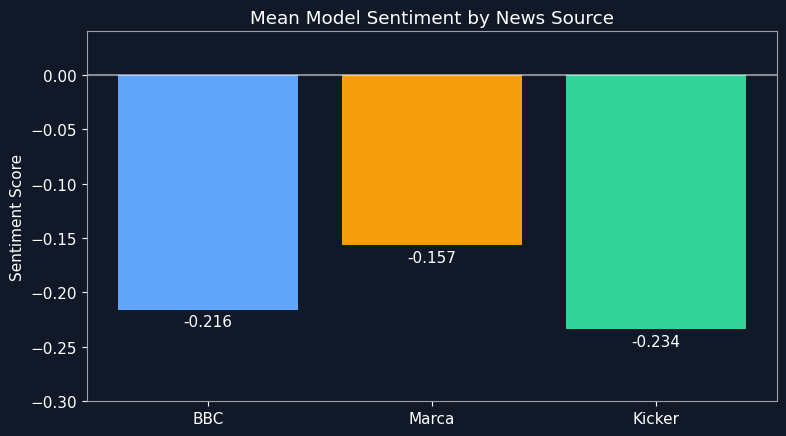

SUCCESS: SENTIMENT FIGURE SAVED


In [17]:
# ============================================================
# 10. FINAL VISUALIZATIONS — SENTIMENT
# ============================================================

plt.rcParams.update({
    "figure.facecolor": "#111827",
    "axes.facecolor": "#111827",
    "savefig.facecolor": "#111827",
    "text.color": "white",
    "axes.labelcolor": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "axes.edgecolor": "#9CA3AF",
    "font.size": 11,
    "savefig.dpi": 300
})

colors = {
    "BBC": "#60A5FA",
    "Marca": "#F59E0B",
    "Kicker": "#34D399"
}

def savefig(filename):
    plt.tight_layout()
    plt.savefig(
        RESULTS / filename,
        bbox_inches="tight",
        dpi=300
    )
    plt.show()
    plt.close()

order = ["BBC", "Marca", "Kicker"]

values = sent_means.reindex(order)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.bar(
    order,
    values,
    color=[colors[s] for s in order]
)

ax.set(
    title="Mean Model Sentiment by News Source",
    ylabel="Sentiment Score",
    ylim=(-0.30, 0.04)
)

ax.axhline(
    0,
    color="white",
    alpha=0.5
)

for i, value in enumerate(values):
    ax.text(
        i,
        value - 0.015,
        f"{value:.3f}",
        ha="center",
        color="white"
    )

savefig("FINAL_01_sentiment.png")

print("SUCCESS: SENTIMENT FIGURE SAVED")

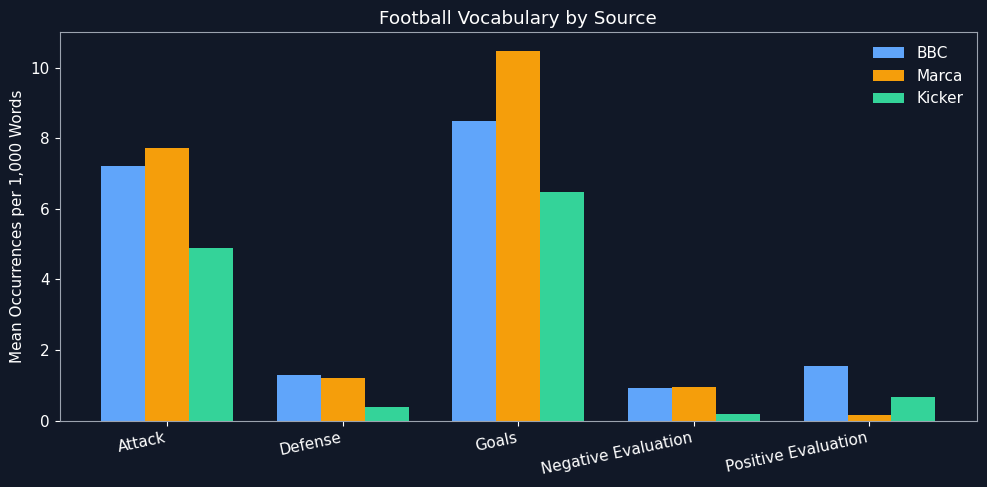

SUCCESS: VOCABULARY FIGURE SAVED


In [18]:
# ============================================================
# 10. FINAL VISUALIZATIONS — VOCABULARY
# ============================================================

categories = [
    "Attack",
    "Defense",
    "Goals",
    "Negative Evaluation",
    "Positive Evaluation"
]

v = vocab_summary.reindex(categories)[order]

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(categories))
width = 0.25

for k, source in enumerate(order):

    ax.bar(
        x + (k - 1) * width,
        v[source],
        width=width,
        color=colors[source],
        label=source
    )

ax.set_xticks(
    x,
    categories,
    rotation=12,
    ha="right"
)

ax.set(
    title="Football Vocabulary by Source",
    ylabel="Mean Occurrences per 1,000 Words"
)

ax.legend(
    frameon=False,
    labelcolor="white"
)

savefig("FINAL_02_vocabulary.png")

print("SUCCESS: VOCABULARY FIGURE SAVED")

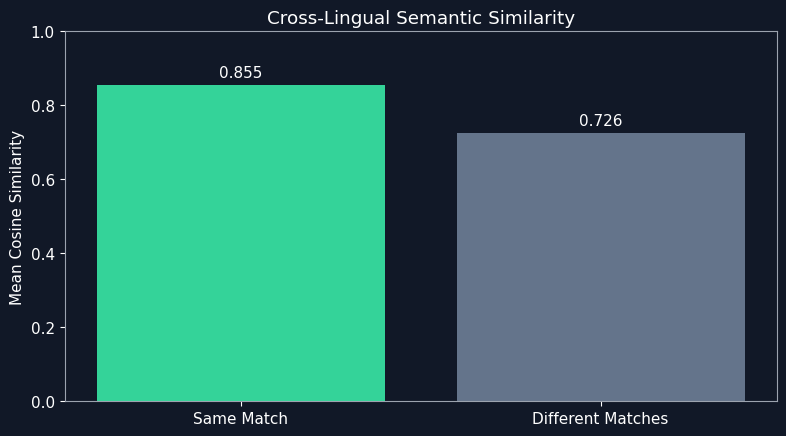

SUCCESS: SEMANTIC SIMILARITY FIGURE SAVED


In [19]:
# ============================================================
# 10. FINAL VISUALIZATIONS — SEMANTIC SIMILARITY
# ============================================================

fig, ax = plt.subplots(figsize=(8, 4.5))

similarity_values = [
    sim.loc[
        sim["same_match"],
        "cosine_similarity"
    ].mean(),

    sim.loc[
        ~sim["same_match"],
        "cosine_similarity"
    ].mean()
]

bars = ax.bar(
    ["Same Match", "Different Matches"],
    similarity_values,
    color=["#34D399", "#64748B"]
)

ax.set(
    title="Cross-Lingual Semantic Similarity",
    ylabel="Mean Cosine Similarity",
    ylim=(0, 1)
)

for bar, value in zip(bars, similarity_values):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        color="white"
    )

savefig("FINAL_03_semantic_similarity.png")

print("SUCCESS: SEMANTIC SIMILARITY FIGURE SAVED")

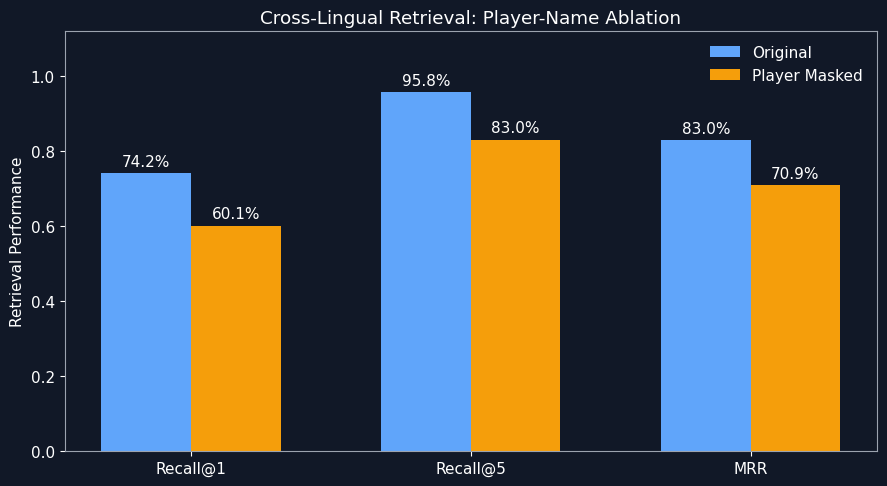

SUCCESS: RETRIEVAL ABLATION FIGURE SAVED


In [20]:
# ============================================================
# 10. FINAL VISUALIZATIONS — RETRIEVAL ABLATION
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

metrics = [
    "Recall@1",
    "Recall@5",
    "MRR"
]

original_values = summary_original.to_numpy()
ablation_values = summary_ablation.to_numpy()

x = np.arange(len(metrics))
width = 0.32

conditions = [
    (
        -width / 2,
        original_values,
        "Original",
        "#60A5FA"
    ),
    (
        width / 2,
        ablation_values,
        "Player Masked",
        "#F59E0B"
    )
]

for shift, values, label, color in conditions:

    bars = ax.bar(
        x + shift,
        values,
        width=width,
        label=label,
        color=color
    )

    for bar, value in zip(bars, values):

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.02,
            f"{value:.1%}",
            ha="center",
            color="white"
        )

ax.set_xticks(x, metrics)

ax.set(
    title="Cross-Lingual Retrieval: Player-Name Ablation",
    ylabel="Retrieval Performance",
    ylim=(0, 1.12)
)

ax.legend(
    frameon=False,
    labelcolor="white"
)

savefig("FINAL_04_retrieval_ablation.png")

print("SUCCESS: RETRIEVAL ABLATION FIGURE SAVED")

## 11. Conclusions and Limitations

### Main Findings

**1. Multilingual Semantic Similarity**

Articles describing the same UEFA Euro 2024 match exhibit higher semantic similarity than articles describing different matches.

- Same-match mean cosine similarity: approximately 0.855
- Different-match mean cosine similarity: approximately 0.726
- Difference: approximately 0.129

The match-level statistical analysis supports this difference.

**2. Cross-Lingual Retrieval**

Multilingual embeddings successfully retrieve corresponding football reports across the three news sources.

- Recall@1: approximately 74.2%
- Recall@5: approximately 95.8%
- Mean Reciprocal Rank: approximately 0.830

**3. Player Information Ablation**

Removing player-specific information reduces retrieval performance.

- Original Recall@1: approximately 74.2%
- Player-masked Recall@1: approximately 60.1%
- Performance decrease: approximately 14.1 percentage points

This suggests that identifiable player information contributes to cross-lingual match retrieval.

**4. Sentiment Analysis**

The Friedman test identifies statistically significant differences in model-estimated sentiment across sources.

However, these results should be interpreted cautiously because the sentiment model was not specifically trained on football journalism.

### Limitations

- **Source-language confounding:** Each source represents a single language, preventing separation of language effects from editorial differences.
- **Dataset size:** The study covers 51 matches and 153 reports from one tournament.
- **Domain mismatch:** The sentiment model was primarily developed for social-media text.
- **Vocabulary comparability:** The manually constructed multilingual dictionaries were not independently validated for equivalent coverage.
- **Model dependence:** Semantic and retrieval results depend on the selected multilingual embedding model.
- **Evaluation dependence:** Multiple retrieval queries originate from the same matches, motivating match-cluster uncertainty estimation.
- **Manual validation:** AI-assisted sentiment annotations should not be treated as independent human ground truth.

### Reproducibility

The final analysis automatically reconstructs the corrected v2 dataset from the public SocCor repository and retrieves the validated cached NLP outputs from the public project repository.

Dataset reproducibility is verified using an exact SHA256 fingerprint across eight validated columns and all 153 documents.

Document ordering and alignment with the cached sentiment results and embedding matrices are also verified automatically.

The notebook recomputes the final statistical analyses, retrieval metrics, ablation comparisons, and visualizations without requiring personal Google Drive access.

The optional upstream model regeneration pipeline is included for methodological transparency but has not been independently validated as a complete end-to-end execution.

All required reproducibility artifacts and execution instructions are available at:

https://github.com/JaviMontava/CDS321-Final-NLP-Project

### Final Conclusion

Multilingual NLP methods can identify substantial semantic correspondence between football reports written in different languages.

Cross-lingual retrieval performance is strong, while the player-information ablation demonstrates that identifiable entities contribute meaningfully to retrieval accuracy.

The results provide evidence of useful multilingual semantic representations, while highlighting important methodological limitations when comparing language-specific news sources.